In [2]:
%pip install shap



   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import shap

from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", None)

In [3]:
df = pd.read_csv(
    "../data/processed/loan_data_feature_engineered.csv"
)

X = df.drop(columns=["Default"])
y = df["Default"]

print("Dataset shape:", df.shape)

Dataset shape: (255347, 18)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (204277, 17)
Testing shape: (51070, 17)


In [5]:
logistic_model = joblib.load(
    "../models/logistic_baseline.pkl"
)

print("LoanGuard model loaded successfully.")

LoanGuard model loaded successfully.


In [6]:
preprocessor = logistic_model.named_steps["preprocessor"]
classifier = logistic_model.named_steps["classifier"]

X_test_transformed = preprocessor.transform(X_test)

print("Original shape:", X_test.shape)
print("Transformed shape:", X_test_transformed.shape)

Original shape: (51070, 17)
Transformed shape: (51070, 32)


In [7]:
feature_names = preprocessor.get_feature_names_out()

print("Number of features:", len(feature_names))
print(feature_names[:20])

Number of features: 32
['num__Age' 'num__Income' 'num__LoanAmount' 'num__CreditScore'
 'num__MonthsEmployed' 'num__NumCreditLines' 'num__InterestRate'
 'num__LoanTerm' 'num__DTIRatio' 'num__LoanToIncomeRatio'
 "cat__Education_Bachelor's" 'cat__Education_High School'
 "cat__Education_Master's" 'cat__Education_PhD'
 'cat__EmploymentType_Full-time' 'cat__EmploymentType_Part-time'
 'cat__EmploymentType_Self-employed' 'cat__EmploymentType_Unemployed'
 'cat__MaritalStatus_Divorced' 'cat__MaritalStatus_Married']


In [8]:
explainer = shap.LinearExplainer(
    classifier,
    X_test_transformed
)

print("SHAP explainer created successfully.")

Background dataset has 51070 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=51070 when initializing the masker.


SHAP explainer created successfully.


In [9]:
shap_values = explainer.shap_values(
    X_test_transformed
)

print("SHAP values calculated.")
print("SHAP shape:", shap_values.shape)

SHAP values calculated.
SHAP shape: (51070, 32)


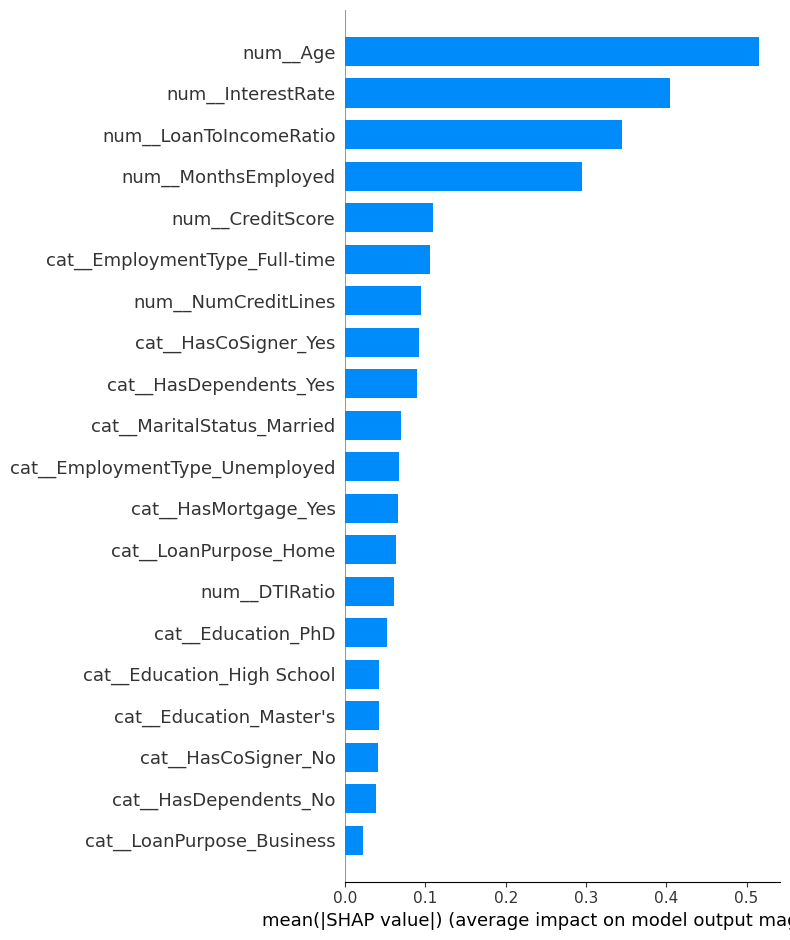

In [10]:
shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names,
    plot_type="bar"
)

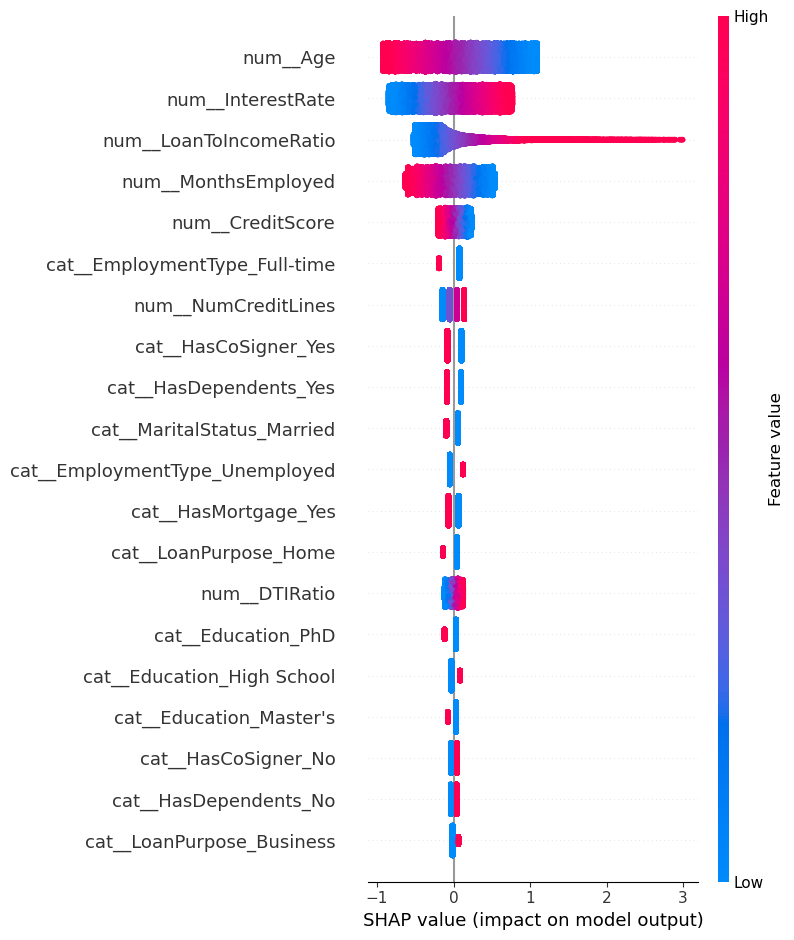

In [11]:
shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names
)

In [12]:
sample_index = 0

sample = X_test.iloc[[sample_index]]

sample_probability = logistic_model.predict_proba(sample)[0, 1]

sample_prediction = int(
    sample_probability >= 0.65
)

print("Default Probability:", round(sample_probability, 4))
print("Prediction:", sample_prediction)

Default Probability: 0.192
Prediction: 0


In [13]:
sample_transformed = preprocessor.transform(sample)

sample_shap = explainer.shap_values(
    sample_transformed
)

print("Individual SHAP values calculated.")

Individual SHAP values calculated.


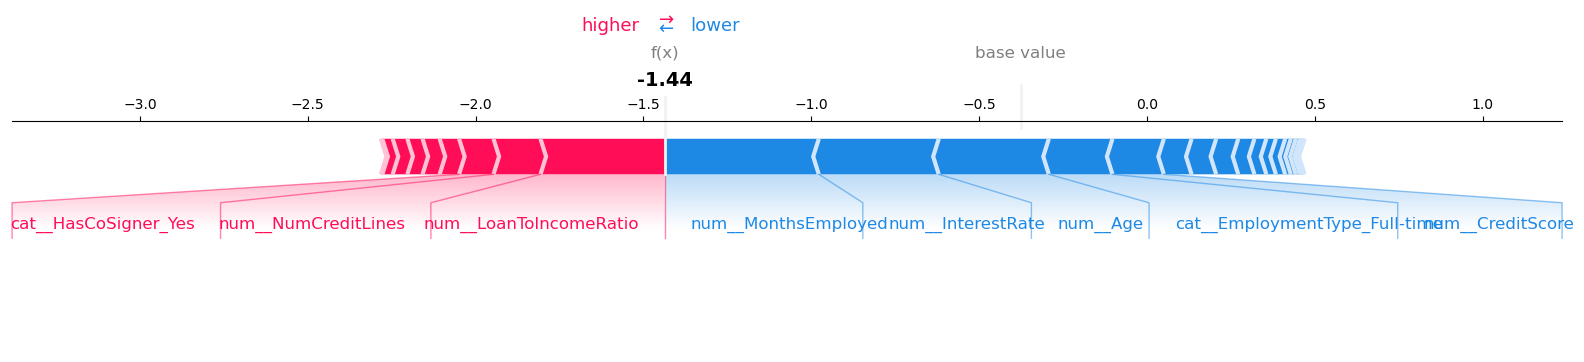

In [14]:
shap.force_plot(
    explainer.expected_value,
    sample_shap[0],
    feature_names=feature_names,
    matplotlib=True
)

plt.show()

In [15]:
# Create a readable SHAP explanation table

sample_shap_values = sample_shap[0]

explanation_df = pd.DataFrame({
    "Feature": feature_names,
    "SHAP_Value": sample_shap_values
})

# Calculate absolute contribution
explanation_df["Absolute_Impact"] = (
    explanation_df["SHAP_Value"].abs()
)

# Sort by strongest impact
explanation_df = explanation_df.sort_values(
    "Absolute_Impact",
    ascending=False
)

explanation_df.head(10)

,Feature,SHAP_Value,Absolute_Impact
4,num__MonthsEmployed,-0.459011,0.459011
9,num__LoanToIncomeRatio,0.369980,0.369980
6,num__InterestRate,-0.357346,0.357346
0,num__Age,-0.327918,0.327918
14,cat__EmploymentType_Full-time,-0.189490,0.189490
3,num__CreditScore,-0.153103,0.153103
5,num__NumCreditLines,0.139996,0.139996
31,cat__HasCoSigner_Yes,0.102544,0.102544
24,cat__HasDependents_Yes,-0.082604,0.082604
12,cat__Education_Master's,-0.073196,0.073196


In [16]:
# Separate factors pushing prediction higher/lower

positive_factors = explanation_df[
    explanation_df["SHAP_Value"] > 0
].head(5)

negative_factors = explanation_df[
    explanation_df["SHAP_Value"] < 0
].head(5)

print("Factors pushing model output higher:")
display(positive_factors[["Feature", "SHAP_Value"]])

print("\nFactors pushing model output lower:")
display(negative_factors[["Feature", "SHAP_Value"]])

Factors pushing model output higher:


,Feature,SHAP_Value
9,num__LoanToIncomeRatio,0.369980
5,num__NumCreditLines,0.139996
31,cat__HasCoSigner_Yes,0.102544
19,cat__MaritalStatus_Married,0.057854
8,num__DTIRatio,0.050951



Factors pushing model output lower:


,Feature,SHAP_Value
4,num__MonthsEmployed,-0.459011
6,num__InterestRate,-0.357346
0,num__Age,-0.327918
14,cat__EmploymentType_Full-time,-0.189490
3,num__CreditScore,-0.153103


In [17]:
def clean_feature_name(feature):

    feature = feature.replace("num_", "")
    feature = feature.replace("cat_", "")

    feature = feature.replace("_", " ")

    return feature

In [18]:
explanation_df["Readable_Feature"] = (
    explanation_df["Feature"].apply(clean_feature_name)
)

explanation_df[
    ["Readable_Feature", "SHAP_Value", "Absolute_Impact"]
].head(10)

,Readable_Feature,SHAP_Value,Absolute_Impact
4,MonthsEmployed,-0.459011,0.459011
9,LoanToIncomeRatio,0.369980,0.369980
6,InterestRate,-0.357346,0.357346
0,Age,-0.327918,0.327918
14,EmploymentType Full-time,-0.189490,0.189490
3,CreditScore,-0.153103,0.153103
5,NumCreditLines,0.139996,0.139996
31,HasCoSigner Yes,0.102544,0.102544
24,HasDependents Yes,-0.082604,0.082604
12,Education Master's,-0.073196,0.073196


In [19]:
top_positive = explanation_df[
    explanation_df["SHAP_Value"] > 0
].head(3)

top_negative = explanation_df[
    explanation_df["SHAP_Value"] < 0
].head(3)

print("Top factors increasing predicted risk:")

for _, row in top_positive.iterrows():
    print(
        f"↑ {row['Readable_Feature']}: "
        f"{row['SHAP_Value']:.3f}"
    )

print("\nTop factors decreasing predicted risk:")

for _, row in top_negative.iterrows():
    print(
        f"↓ {row['Readable_Feature']}: "
        f"{abs(row['SHAP_Value']):.3f}"
    )

Top factors increasing predicted risk:
↑  LoanToIncomeRatio: 0.370
↑  NumCreditLines: 0.140
↑  HasCoSigner Yes: 0.103

Top factors decreasing predicted risk:
↓  MonthsEmployed: 0.459
↓  InterestRate: 0.357
↓  Age: 0.328


In [21]:
# Create transformed training data for SHAP background

X_train_transformed = preprocessor.transform(X_train)

print("Transformed training shape:", X_train_transformed.shape)

# Use first 500 training samples as SHAP background
shap_background = X_train_transformed[:500]

# Save SHAP background
joblib.dump(
    shap_background,
    "../models/shap_background.pkl"
)

# Save feature names
joblib.dump(
    feature_names,
    "../models/shap_feature_names.pkl"
)

print("SHAP background saved successfully.")

Transformed training shape: (204277, 32)
SHAP background saved successfully.
